# 001 pilot viability check

本 notebook 只读取 `runs/agentic-credit-assignment/exp_001` 的固定产物，检查三件事：

1. 一条成功轨迹和一条失败轨迹的最后两个交互 step；
2. 两个训练 task 的跨轨迹图、ID 查询表和 credit 指标；
3. rollout、优化器与评测是否健康。

图的构造直接调用 third-party GraphGPO 的 `recipe.GraphGPO.core_graph.ComplexGraph.from_data`。旧 notebook 的自定义合并逻辑不再使用。可视化只画高频节点子图以保持可读性；`graph_objects` 保存完整图，完整节点/边指标保存在 `node_tables` / `edge_tables`。

In [1]:
import json
import os
import sys
from collections import Counter, defaultdict
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT = Path('/cephfs/wenhaozhang/projects/agentic-credit-assignment')
RUN = Path('/cephfs/wenhaozhang/runs/agentic-credit-assignment/exp_001')
THIRD_PARTY = PROJECT / 'third_party/verl-agent'
sys.path.insert(0, str(THIRD_PARTY))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mpl-aca')

from recipe.GraphGPO.core_graph import ComplexGraph

def read_jsonl(path):
    with Path(path).open() as f:
        return [json.loads(line) for line in f if line.strip()]

rollout_groups = read_jsonl(RUN / 'samples/rollouts.jsonl')
saved_graph_rows = read_jsonl(RUN / 'samples/graphs.jsonl')
train_metrics = pd.DataFrame(read_jsonl(RUN / 'metrics/train_metrics.jsonl'))
eval_metrics = json.loads((RUN / 'metrics/eval_metrics.json').read_text())

summary = []
for group in rollout_groups:
    trajectories = group['trajectories']
    summary.append({
        'phase': group['phase'],
        'task_uid': group['task_uid'],
        'task': group['task_description'],
        'rollouts': len(trajectories),
        'successes': sum(bool(t['success']) for t in trajectories),
        'success_rate': np.mean([bool(t['success']) for t in trajectories]),
        'mean_steps': np.mean([len(t['steps']) for t in trajectories]),
        'action_valid_rate': np.mean([
            bool(s.get('action_valid', False))
            for t in trajectories for s in t['steps']
        ]),
        'fallback': group.get('diagnostics', {}).get('fallback'),
    })
summary_df = pd.DataFrame(summary)
display(summary_df.style.format({'success_rate': '{:.2%}', 'action_valid_rate': '{:.2%}', 'mean_steps': '{:.1f}'}))

/root/micromamba/envs/ac-verl-agent/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-09 19:50:49,924	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


,phase,task_uid,task,rollouts,successes,success_rate,mean_steps,action_valid_rate,fallback
0,train,43927680-4556-43d3-a64f-73a5f2a13f28,put two creditcard in armchair.,8,0,0.00%,30.0,63.75%,insufficient_successes
1,train,4eebfb65-b963-4cbf-8ae9-fa823524c4db,heat some apple and put it in garbagecan.,8,1,12.50%,29.8,59.66%,insufficient_successes
2,eval,33c8f40d-8597-426f-8075-317b2ed89eda,put a cool tomato in countertop.,8,0,0.00%,30.0,50.83%,nan
3,eval,354f0552-b583-459c-81fa-6ab402922967,clean some ladle and put it in countertop.,6,1,16.67%,26.7,48.12%,nan


## 1. 成功/失败 rollout 的最后两个 step

优先从训练 rollout 中选择同一 task 的一成功一失败轨迹，便于直接比较。这里的 `e_t` 是环境执行结果：包含环境返回的 observation、即时环境 reward、done/won 和动作是否合法；`s_{t+1}` 是送入下一步图构造的完整状态。

In [2]:
train_groups = [g for g in rollout_groups if g['phase'] == 'train']
all_train = [(g, t) for g in train_groups for t in g['trajectories']]
success_pair = next(((g, t) for g, t in all_train if t['success']), None)
if success_pair is None:
    raise RuntimeError('Pilot 中没有成功训练 rollout，无法完成成功/失败成对检查。')
success_group, success_traj = success_pair
failure_pair = next(
    ((g, t) for g, t in all_train if g['task_uid'] == success_group['task_uid'] and not t['success']),
    next((x for x in all_train if not x[1]['success']), None),
)
failure_group, failure_traj = failure_pair

def render_last_steps(label, group, traj, n=2):
    display(Markdown(
        f"### {label}: `{group['task_description']}`  "
        f"\ntrajectory=`{traj['trajectory_id']}`, steps={len(traj['steps'])}, "
        f"final $R_i$={traj['R']}, success={traj['success']}"
    ))
    for s in traj['steps'][-n:]:
        t = s['step']
        env = {
            'executed_action': s['action'],
            'action_valid': s.get('action_valid'),
            'raw_observation': s.get('raw_observation'),
            'environment_reward': s.get('environment_reward'),
            'done': s.get('done'),
            'won': s.get('won'),
            'goal_condition_success_rate': s.get('goal_condition_success_rate'),
        }
        display(Markdown(f"#### step {t}: $s_{{{t}}} \\rightarrow a_{{{t}}} \\rightarrow e_{{{t}}} \\rightarrow s_{{{t+1}}}$"))
        display(Markdown('**s_t**\n```text\n' + str(s['state']) + '\n```'))
        display(Markdown('**prompt**\n```text\n' + str(s['prompt']) + '\n```'))
        display(Markdown('**raw output**\n```text\n' + str(s['raw_response']) + '\n```'))
        display(pd.DataFrame([{
            'a_t (extracted)': s['action'],
            'credit r_t': s.get('credit'),
            'omega_t': s.get('omega'),
            'A_it': s.get('A_it'),
        }]))
        display(Markdown('**e_t (environment execution)**\n```json\n' + json.dumps(env, ensure_ascii=False, indent=2) + '\n```'))
        display(Markdown('**s_{t+1}**\n```text\n' + str(s['next_state']) + '\n```'))

render_last_steps('成功 rollout', success_group, success_traj)
render_last_steps('失败 rollout', failure_group, failure_traj)

### 成功 rollout: `heat some apple and put it in garbagecan.`  
trajectory=`c8793f5e-fb6f-4540-9c00-18f16364c102`, steps=28, final $R_i$=10.0, success=True

#### step 26: $s_{26} \rightarrow a_{26} \rightarrow e_{26} \rightarrow s_{27}$

**s_t**
```text
This is a hot apple 1. Location: garbagecan 1. Items in hand (status): apple 1(heated).  examine apple 1,examine garbagecan 1,go to cabinet 1,go to cabinet 10,go to cabinet 11,go to cabinet 12,go to cabinet 13,go to cabinet 14,go to cabinet 15,go to cabinet 16,go to cabinet 17,go to cabinet 18,go to cabinet 2,go to cabinet 3,go to cabinet 4,go to cabinet 5,go to cabinet 6,go to cabinet 7,go to cabinet 8,go to cabinet 9,go to coffeemachine 1,go to countertop 1,go to countertop 2,go to countertop 3,go to countertop 4,go to drawer 1,go to drawer 2,go to drawer 3,go to drawer 4,go to drawer 5,go to drawer 6,go to drawer 7,go to fridge 1,go to microwave 1,go to sinkbasin 1,go to stoveburner 1,go to stoveburner 2,go to stoveburner 3,go to stoveburner 4,go to toaster 1,help,inventory,look,move apple 1 to garbagecan 1
```

**prompt**
```text
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user

You are an expert agent operating in the ALFRED Embodied Environment. Your task is to: heat some apple and put it in garbagecan.
Prior to this step, you have already taken 26 step(s). Below are the most recent 2 observations and the corresponding actions you took: [Observation 25: 'Nothing happens. Location: garbagecan 1. Items in hand (status): apple 1(heated). ', Action 25: 'examine apple 1']
[Observation 26: 'This is a hot apple 1. Location: garbagecan 1. Items in hand (status): apple 1(heated). ', Action 26: 'examine apple 1']
You are now at step 27 and your current observation is: This is a hot apple 1. Location: garbagecan 1. Items in hand (status): apple 1(heated). 
Your admissible actions of the current situation are: ['examine apple 1'
 'examine garbagecan 1'
 'go to cabinet 1'
 'go to cabinet 10'
 'go to cabinet 11'
 'go to cabinet 12'
 'go to cabinet 13'
 'go to cabinet 14'
 'go to cabinet 15'
 'go to cabinet 16'
 'go to cabinet 17'
 'go to cabinet 18'
 'go to cabinet 2'
 'go to cabinet 3'
 'go to cabinet 4'
 'go to cabinet 5'
 'go to cabinet 6'
 'go to cabinet 7'
 'go to cabinet 8'
 'go to cabinet 9'
 'go to coffeemachine 1'
 'go to countertop 1'
 'go to countertop 2'
 'go to countertop 3'
 'go to countertop 4'
 'go to drawer 1'
 'go to drawer 2'
 'go to drawer 3'
 'go to drawer 4'
 'go to drawer 5'
 'go to drawer 6'
 'go to drawer 7'
 'go to fridge 1'
 'go to microwave 1'
 'go to sinkbasin 1'
 'go to stoveburner 1'
 'go to stoveburner 2'
 'go to stoveburner 3'
 'go to stoveburner 4'
 'go to toaster 1'
 'inventory'
 'look'
 'move apple 1 to garbagecan 1'].

Now it's your turn to take an action.
You should first reason step-by-step about the current situation. This reasoning process MUST be enclosed within <think> </think> tags. 
Once you've finished your reasoning, you should choose an admissible action for current step and present it within <action> </action> tags.
<|im_end|>
<|im_start|>assistant

```

**raw output**
```text
examine apple 1
```

,a_t (extracted),credit r_t,omega_t,A_it
0,examine apple 1,0.0,1.0,8.823529


... (20 outputs left out)

**raw output**
```text
inventory
```

,a_t (extracted),credit r_t,omega_t,A_it
0,inventory,0.0,1.0,-1.176471


**e_t (environment execution)**
```json
{
  "executed_action": "inventory",
  "action_valid": false,
  "raw_observation": "You are carrying: a apple 1. Location: garbagecan 1. Items in hand (status): apple 1(unprocessed). ",
  "environment_reward": 0.0,
  "done": false,
  "won": 0.0,
  "goal_condition_success_rate": 0.0
}
```

**s_{t+1}**
```text
You are carrying: a apple 1. Location: garbagecan 1. Items in hand (status): apple 1(unprocessed).  examine apple 1,examine garbagecan 1,go to cabinet 1,go to cabinet 10,go to cabinet 11,go to cabinet 12,go to cabinet 13,go to cabinet 14,go to cabinet 15,go to cabinet 16,go to cabinet 17,go to cabinet 18,go to cabinet 2,go to cabinet 3,go to cabinet 4,go to cabinet 5,go to cabinet 6,go to cabinet 7,go to cabinet 8,go to cabinet 9,go to coffeemachine 1,go to countertop 1,go to countertop 2,go to countertop 3,go to countertop 4,go to drawer 1,go to drawer 2,go to drawer 3,go to drawer 4,go to drawer 5,go to drawer 6,go to drawer 7,go to fridge 1,go to microwave 1,go to sinkbasin 1,go to stoveburner 1,go to stoveburner 2,go to stoveburner 3,go to stoveburner 4,go to toaster 1,help,inventory,look,move apple 1 to garbagecan 1
```

## 2. 用 GraphGPO 构造两个 task 的完整图

- 节点：GraphGPO 对 `anchor_obs/next_obs` 做 exact-state merge 后得到的状态；
- 多重边：同一对状态之间允许多个不同 action，也允许同 action 多次出现；
- `s_id` / `a_id` 是本 notebook 额外附加的稳定查询编号，不改变 GraphGPO 构图；
- 图上只标编号，具体文本和全部指标通过 `lookup_state(task_uid, s_id)`、`lookup_action(task_uid, a_id)`、`lookup_edge(task_uid, edge_id)` 查询。

In [3]:
def to_graphgpo_batch(group):
    cols = defaultdict(list)
    row_id = 0
    for traj in group['trajectories']:
        for step in traj['steps']:
            cols['uid'].append(group['task_uid'])
            cols['anchor_obs'].append(step['state'])
            cols['next_obs'].append(step['next_state'])
            cols['text_actions'].append(step['action'])
            cols['executed_actions'].append(step['action'])
            cols['traj_uid'].append(traj['trajectory_id'])
            cols['episode_rewards'].append(float(traj['R']))
            row_id += 1
    batch = {}
    for key, values in cols.items():
        dtype = float if key == 'episode_rewards' else object
        batch[key] = np.asarray(values, dtype=dtype)
    return SimpleNamespace(non_tensor_batch=batch)

graph_objects = {}
for group in train_groups:
    graph_objects.update(ComplexGraph.from_data(to_graphgpo_batch(group), enable_similarity=False))

graph_summary = []
for group in train_groups:
    graph = graph_objects[group['task_uid']]
    graph_summary.append({
        'task_uid': group['task_uid'],
        'task': group['task_description'],
        'GraphGPO nodes': len(graph.nodes),
        'GraphGPO edge instances': sum(1 for _ in graph.edges(data=True)),
        'successful rollouts': sum(t['success'] for t in group['trajectories']),
        'fallback': group['diagnostics'].get('fallback'),
        'selected key states': len(group.get('key_states', [])),
        'segments': len(group.get('segments', [])),
    })
display(pd.DataFrame(graph_summary))

,task_uid,task,GraphGPO nodes,GraphGPO edge instances,successful rollouts,fallback,selected key states,segments
0,43927680-4556-43d3-a64f-73a5f2a13f28,put two creditcard in armchair.,59,240,0,insufficient_successes,0,0
1,4eebfb65-b963-4cbf-8ae9-fa823524c4db,heat some apple and put it in garbagecan.,113,238,1,insufficient_successes,0,0


In [4]:
def finite_mean(values):
    values = [float(x) for x in values if x is not None and np.isfinite(float(x))]
    return float(np.mean(values)) if values else np.nan

def finite_max(values):
    values = [float(x) for x in values if x is not None and np.isfinite(float(x))]
    return float(np.max(values)) if values else np.nan

node_tables, action_tables, edge_tables = {}, {}, {}
task_by_uid = {g['task_uid']: g for g in train_groups}

for uid, graph in graph_objects.items():
    group = task_by_uid[uid]
    node_visits = Counter()
    node_success_trajs = defaultdict(set)
    node_failure_trajs = defaultdict(set)
    action_freq = Counter()
    edge_steps = defaultdict(list)
    for traj in group['trajectories']:
        seen = set()
        for step in traj['steps']:
            u, v, a = step['state'], step['next_state'], step['action']
            node_visits[u] += 1
            seen.add(u); seen.add(v)
            action_freq[a] += 1
            edge_steps[(u, a, v)].append(step)
        if traj['steps']:
            node_visits[traj['steps'][-1]['next_state']] += 1
        target = node_success_trajs if traj['success'] else node_failure_trajs
        for state in seen:
            target[state].add(traj['trajectory_id'])

    ordered_states = sorted(graph.nodes, key=lambda x: (-node_visits[str(x)], str(x)))
    state_id = {str(s): f's{i}' for i, s in enumerate(ordered_states)}
    ordered_actions = sorted(action_freq, key=lambda x: (-action_freq[x], x))
    action_id = {a: f'a{i}' for i, a in enumerate(ordered_actions)}
    key_map = {k['state']: k for k in group.get('key_states', [])}

    node_rows = []
    for state in ordered_states:
        state = str(state)
        key = key_map.get(state, {})
        node_rows.append({
            's_id': state_id[state], 'state': state, 'visit_frequency': node_visits[state],
            'success_traj_support': len(node_success_trajs[state]),
            'failure_traj_support': len(node_failure_trajs[state]),
            'importance_I': key.get('importance', np.nan),
            'coverage_N': key.get('coverage', np.nan),
            'posterior_success': key.get('posterior_mean', np.nan),
            'success_LCB': key.get('lcb', np.nan),
            'earliness_E': key.get('earliness', np.nan),
            'efficiency_Q': key.get('efficiency', np.nan),
        })
    action_rows = [{'a_id': action_id[a], 'action': a, 'frequency': action_freq[a]} for a in ordered_actions]
    edge_rows = []
    for i, ((u, a, v), steps) in enumerate(sorted(edge_steps.items(), key=lambda kv: (-len(kv[1]), kv[0]))):
        edge_rows.append({
            'edge_id': f'e{i}', 'from': state_id[u], 'a_id': action_id[a], 'to': state_id[v],
            'frequency': len(steps), 'action': a,
            'mean_credit_r': finite_mean([s.get('credit') for s in steps]),
            'max_credit_r': finite_max([s.get('credit') for s in steps]),
            'mean_omega': finite_mean([s.get('omega') for s in steps]),
            'mean_A_it': finite_mean([s.get('A_it') for s in steps]),
            'max_A_it': finite_max([s.get('A_it') for s in steps]),
            'valid_rate': np.mean([bool(s.get('action_valid')) for s in steps]),
        })
    node_tables[uid] = pd.DataFrame(node_rows)
    action_tables[uid] = pd.DataFrame(action_rows)
    edge_tables[uid] = pd.DataFrame(edge_rows)

def lookup_state(task_uid, s_id):
    return node_tables[task_uid].query('s_id == @s_id')

def lookup_action(task_uid, a_id):
    return action_tables[task_uid].query('a_id == @a_id')

def lookup_edge(task_uid, edge_id):
    return edge_tables[task_uid].query('edge_id == @edge_id')

print('查询示例：lookup_state(task_uid, "s0"), lookup_action(task_uid, "a0"), lookup_edge(task_uid, "e0")')

查询示例：lookup_state(task_uid, "s0"), lookup_action(task_uid, "a0"), lookup_edge(task_uid, "e0")


### Task: `put two creditcard in armchair.` (`43927680-4556-43d3-a64f-73a5f2a13f28`)

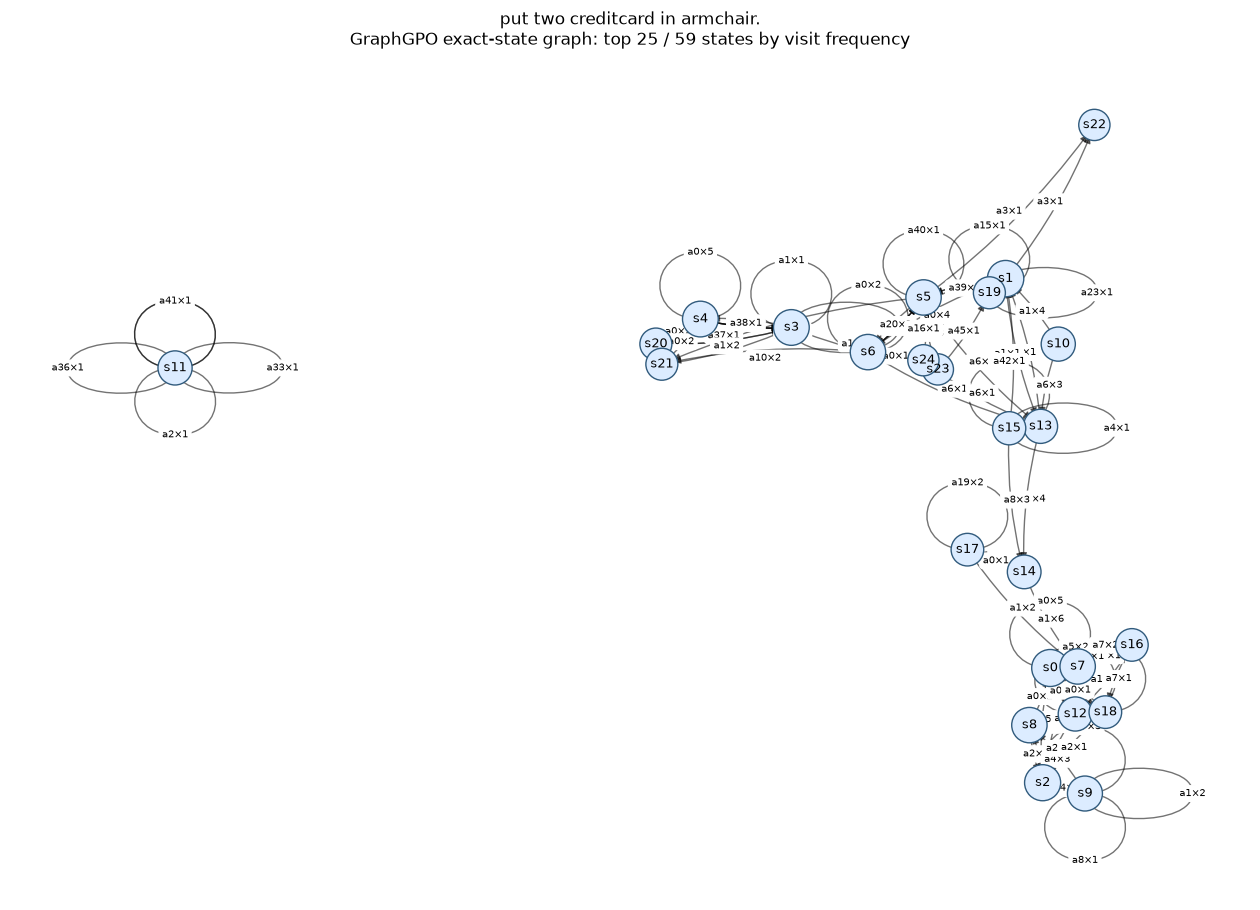

**节点指标（前 20 个；完整表在 `node_tables[task_uid]`）**

,s_id,state,visit_frequency,success_traj_support,failure_traj_support,importance_I,coverage_N,posterior_success,success_LCB,earliness_E,efficiency_Q
0,s0,"On the armchair 1, you see a pillow 1. Location: armchair 1. Items in hand (status): creditcard 3(unprocessed). examine armchair 1,examine creditcard 3,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,move creditcard 3 to armchair 1",16,0,4,nan,nan,nan,nan,nan,nan
1,s1,"You arrive at armchair 1. On the armchair 1, you see a pillow 1. Location: armchair 1. Items in hand (status): nothing. examine armchair 1,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,take pillow 1 from armchair 1",14,0,6,nan,nan,nan,nan,nan,nan
2,s2,"You move the creditcard 3 to the armchair 1. Location: armchair 1. Items in hand (status): nothing. History moving list by you: creditcard 3(unprocessed) from coffeetable 1 move to armchair 1; examine armchair 1,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,take creditcard 3 from armchair 1,take pillow 1 from armchair 1",13,0,4,nan,nan,nan,nan,nan,nan
3,s3,"Nothing happens. Location: armchair 1. Items in hand (status): pillow 1(unprocessed). examine armchair 1,examine pillow 1,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,move pillow 1 to armchair 1",12,0,4,nan,nan,nan,nan,nan,nan
4,s4,"On the armchair 1, you see nothing. Location: armchair 1. Items in hand (status): pillow 1(unprocessed). examine armchair 1,examine pillow 1,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,move pillow 1 to armchair 1",12,0,4,nan,nan,nan,nan,nan,nan
5,s5,"Nothing happens. Location: armchair 1. Items in hand (status): nothing. examine armchair 1,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,take pillow 1 from armchair 1",11,0,4,nan,nan,nan,nan,nan,nan
6,s6,"On the armchair 1, you see a pillow 1. Location: armchair 1. Items in hand (status): nothing. examine armchair 1,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,take pillow 1 from armchair 1",11,0,4,nan,nan,nan,nan,nan,nan
7,s7,"You arrive at armchair 1. On the armchair 1, you see a pillow 1. Location: armchair 1. Items in hand (status): creditcard 3(unprocessed). examine armchair 1,examine creditcard 3,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,move creditcard 3 to armchair 1",11,0,6,nan,nan,nan,nan,nan,nan
8,s8,"You pick up the creditcard 3 from the armchair 1. Location: armchair 1. Items in hand (status): creditcard 3(unprocessed). examine armchair 1,examine creditcard 3,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,move creditcard 3 to armchair 1",11,0,4,nan,nan,nan,nan,nan,nan
9,s9,"Nothing happens. Location: armchair 1. Items in hand (status): nothing. History moving list by you: creditcard 3(unprocessed) from coffeetable 1 move to armchair 1; examine armchair 1,go to coffeetable 1,go to coffeetable 2,go to diningtable 1,go to drawer 1,go to garbagecan 1,go to sidetable 1,go to sofa 1,help,inventory,look,take creditcard 3 from armchair 1,take pillow 1 from armchair 1",10,0,3,nan,nan,nan,nan,nan,nan


**动作编号（完整表）**

,a_id,action,frequency
0,a0,examine armchair 1,47
1,a1,go to armchair 1,47
2,a2,move creditcard 3 to armchair 1,16
3,a3,go to drawer 1,12
4,a4,take creditcard 3 from armchair 1,12
5,a5,examine creditcard 3,11
6,a6,go to coffeetable 1,11
7,a7,inventory,8
8,a8,take creditcard 3 from coffeetable 1,8
9,a9,open drawer 1,6


**边指标（按频次前 30 个；完整表在 `edge_tables[task_uid]`）**

,edge_id,from,a_id,to,frequency,action,mean_credit_r,max_credit_r,mean_omega,mean_A_it,max_A_it,valid_rate
0,e0,s2,a4,s8,6,take creditcard 3 from armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
1,e1,s14,a1,s7,6,go to armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
2,e2,s0,a0,s0,5,examine armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
3,e3,s4,a0,s4,5,examine armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
4,e4,s8,a2,s2,5,move creditcard 3 to armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
5,e5,s10,a1,s1,4,go to armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
6,e6,s5,a0,s6,4,examine armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,0.7500
7,e7,s7,a0,s0,4,examine armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
8,e8,s1,a0,s6,4,examine armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
9,e9,s1,a1,s5,4,go to armchair 1,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000


### Task: `heat some apple and put it in garbagecan.` (`4eebfb65-b963-4cbf-8ae9-fa823524c4db`)

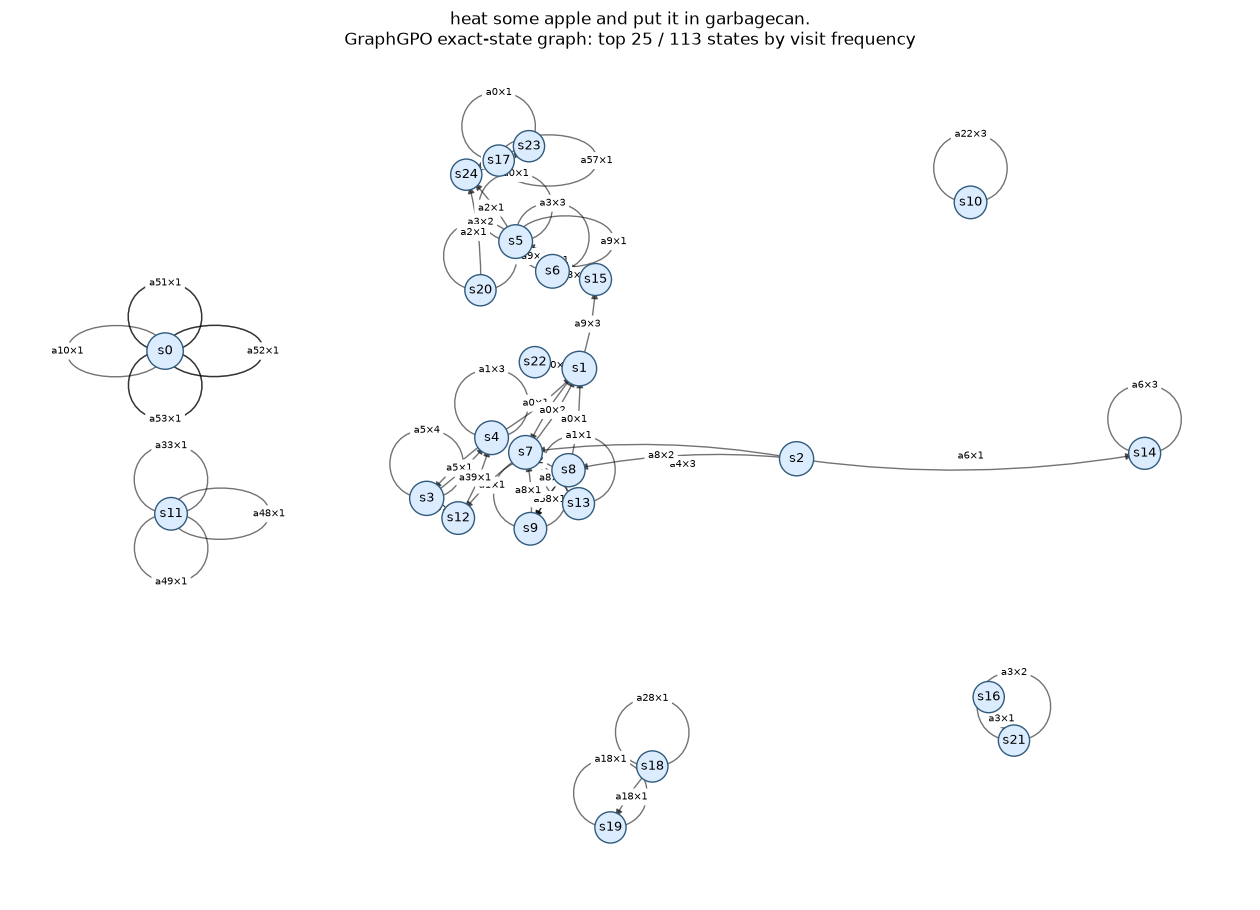

**节点指标（前 20 个；完整表在 `node_tables[task_uid]`）**

,s_id,state,visit_frequency,success_traj_support,failure_traj_support,importance_I,coverage_N,posterior_success,success_LCB,earliness_E,efficiency_Q
0,s0,"Nothing happens. Location: cabinet 17. Items in hand (status): nothing. close cabinet 17,examine cabinet 17,go to cabinet 1,go to cabinet 10,go to cabinet 11,go to cabinet 12,go to cabinet 13,go to cabinet 14,go to cabinet 15,go to cabinet 16,go to cabinet 18,go to cabinet 2,go to cabinet 3,go to cabinet 4,go to cabinet 5,go to cabinet 6,go to cabinet 7,go to cabinet 8,go to cabinet 9,go to coffeemachine 1,go to countertop 1,go to countertop 2,go to countertop 3,go to countertop 4,go to drawer 1,go to drawer 2,go to drawer 3,go to drawer 4,go to drawer 5,go to drawer 6,go to drawer 7,go to fridge 1,go to garbagecan 1,go to microwave 1,go to sinkbasin 1,go to stoveburner 1,go to stoveburner 2,go to stoveburner 3,go to stoveburner 4,go to toaster 1,help,inventory,look",14,0,1,nan,nan,nan,nan,nan,nan
1,s1,"You arrive at garbagecan 1. On the garbagecan 1, you see a apple 1, and a tomato 1. Location: garbagecan 1. Items in hand (status): nothing. examine garbagecan 1,go to cabinet 1,go to cabinet 10,go to cabinet 11,go to cabinet 12,go to cabinet 13,go to cabinet 14,go to cabinet 15,go to cabinet 16,go to cabinet 17,go to cabinet 18,go to cabinet 2,go to cabinet 3,go to cabinet 4,go to cabinet 5,go to cabinet 6,go to cabinet 7,go to cabinet 8,go to cabinet 9,go to coffeemachine 1,go to countertop 1,go to countertop 2,go to countertop 3,go to countertop 4,go to drawer 1,go to drawer 2,go to drawer 3,go to drawer 4,go to drawer 5,go to drawer 6,go to drawer 7,go to fridge 1,go to microwave 1,go to sinkbasin 1,go to stoveburner 1,go to stoveburner 2,go to stoveburner 3,go to stoveburner 4,go to toaster 1,help,inventory,look,take apple 1 from garbagecan 1,take tomato 1 from garbagecan 1",9,1,4,nan,nan,nan,nan,nan,nan
2,s2,"-= Welcome to TextWorld, ALFRED! =- You are in the middle of a room. Looking quickly around you, you see a cabinet 18, a cabinet 17, a cabinet 16, a cabinet 15, a cabinet 14, a cabinet 13, a cabinet 12, a cabinet 11, a cabinet 10, a cabinet 9, a cabinet 8, a cabinet 7, a cabinet 6, a cabinet 5, a cabinet 4, a cabinet 3, a cabinet 2, a cabinet 1, a coffeemachine 1, a countertop 4, a countertop 3, a countertop 2, a countertop 1, a drawer 7, a drawer 6, a drawer 5, a drawer 4, a drawer 3, a drawer 2, a drawer 1, a fridge 1, a garbagecan 1, a microwave 1, a sinkbasin 1, a stoveburner 4, a stoveburner 3, a stoveburner 2, a stoveburner 1, and a toaster 1. Your task is to: heat some apple and put it in garbagecan. Location: middle of a room. Items in hand (status): nothing. go to cabinet 1,go to cabinet 10,go to cabinet 11,go to cabinet 12,go to cabinet 13,go to cabinet 14,go to cabinet 15,go to cabinet 16,go to cabinet 17,go to cabinet 18,go to cabinet 2,go to cabinet 3,go to cabinet 4,go to cabinet 5,go to cabinet 6,go to cabinet 7,go to cabinet 8,go to cabinet 9,go to coffeemachine 1,go to countertop 1,go to countertop 2,go to countertop 3,go to countertop 4,go to drawer 1,go to drawer 2,go to drawer 3,go to drawer 4,go to drawer 5,go to drawer 6,go to drawer 7,go to fridge 1,go to garbagecan 1,go to microwave 1,go to sinkbasin 1,go to stoveburner 1,go to stoveburner 2,go to stoveburner 3,go to stoveburner 4,go to toaster 1,help,inventory,look",8,1,7,nan,nan,nan,nan,nan,nan
3,s3,"The fridge 1 is closed. Location: fridge 1. Items in hand (status): nothing. examine fridge 1,go to cabinet 1,go to cabinet 10,go to cabinet 11,go to cabinet 12,go to cabinet 13,go to cabinet 14,go to cabinet 15,go to cabinet 16,go to cabinet 17,go to cabinet 18,go to cabinet 2,go to cabinet 3,go to cabinet 4,go to cabinet 5,go to cabinet 6,go to cabinet 7,go to cabinet 8,go to cabinet 9,go to coffeemachine 1,go to countertop 1,go to countertop 2,go to countertop 3,go to countertop 4,go to drawer 1,go to drawer 2,go to drawer 3,go to drawer 4,go to drawer 5,go to drawer 6,go to drawer 7,go to 

**动作编号（完整表）**

,a_id,action,frequency
0,a0,go to garbagecan 1,22
1,a1,go to fridge 1,21
2,a2,go to microwave 1,17
3,a3,examine apple 1,16
4,a4,go to cabinet 1,13
...,...,...,...
65,a65,take bowl 1 from fridge 1,1
66,a66,take bowl 1 from microwave 1,1
67,a67,take plate 1 from cabinet 1,1
68,a68,take tomato 1 from garbagecan 1,1


**边指标（按频次前 30 个；完整表在 `edge_tables[task_uid]`）**

,edge_id,from,a_id,to,frequency,action,mean_credit_r,max_credit_r,mean_omega,mean_A_it,max_A_it,valid_rate
0,e0,s0,a11,s0,5,go_to_cabinet_1,0.0000,0.0000,1.0000,-1.1765,-1.1765,0.0000
1,e1,s3,a5,s3,4,examine fridge 1,0.0000,0.0000,1.0000,-1.1765,-1.1765,0.5000
2,e2,s2,a4,s8,3,go to cabinet 1,0.0000,0.0000,1.0000,2.1569,8.8235,1.0000
3,e3,s4,a1,s4,3,go to fridge 1,0.0000,0.0000,1.0000,-1.1765,-1.1765,0.0000
4,e4,s10,a22,s10,3,turn on microwave 1,0.0000,0.0000,1.0000,-1.1765,-1.1765,0.0000
5,e5,s6,a3,s6,3,examine apple 1,0.0000,0.0000,1.0000,-1.1765,-1.1765,1.0000
6,e6,s14,a6,s14,3,inventory,0.0000,0.0000,1.0000,-1.1765,-1.1765,1.0000
7,e7,s1,a9,s15,3,take apple 1 from garbagecan 1,0.0000,0.0000,1.0000,2.1569,8.8235,1.0000
8,e8,s2,a8,s7,2,go to countertop 1,0.0000,0.0000,1.0000,-1.1765,-1.1765,1.0000
9,e9,s9,a4,s9,2,go to cabinet 1,0.0000,0.0000,1.0000,-1.1765,-1.1765,0.0000


In [5]:
def plot_task_graph(uid, top_n=25):
    nodes = node_tables[uid]
    edges = edge_tables[uid]
    keep = set(nodes.nlargest(top_n, 'visit_frequency')['s_id'])
    view = nx.MultiDiGraph()
    for row in nodes[nodes.s_id.isin(keep)].itertuples():
        view.add_node(row.s_id, frequency=row.visit_frequency, importance=row.importance_I)
    for row in edges.itertuples():
        if row._2 in keep and row.to in keep:  # `_2` is pandas' sanitized `from` field
            view.add_edge(row._2, row.to, key=row.edge_id, label=f'{row.a_id}×{row.frequency}', credit=row.mean_credit_r)

    fig, ax = plt.subplots(figsize=(16, 11))
    pos = nx.spring_layout(view, seed=7, k=1.3 / max(1, np.sqrt(len(view))))
    sizes = [350 + 90 * np.sqrt(view.nodes[n]['frequency']) for n in view.nodes]
    nx.draw_networkx_nodes(view, pos, node_size=sizes, node_color='#dcecff', edgecolors='#315b7d', ax=ax)
    nx.draw_networkx_labels(view, pos, font_size=9, ax=ax)
    nx.draw_networkx_edges(view, pos, width=1.0, alpha=0.55, arrows=True, connectionstyle='arc3,rad=0.08', ax=ax)
    labels = {(u, v, k): d['label'] for u, v, k, d in view.edges(keys=True, data=True)}
    nx.draw_networkx_edge_labels(view, pos, edge_labels=labels, font_size=7, rotate=False, ax=ax)
    task = task_by_uid[uid]['task_description']
    ax.set_title(f'{task}\nGraphGPO exact-state graph: top {len(keep)} / {len(nodes)} states by visit frequency')
    ax.axis('off')
    plt.show()

for uid in graph_objects:
    display(Markdown(f"### Task: `{task_by_uid[uid]['task_description']}` (`{uid}`)"))
    plot_task_graph(uid)
    display(Markdown('**节点指标（前 20 个；完整表在 `node_tables[task_uid]`）**'))
    display(node_tables[uid].head(20).style.format(precision=4))
    display(Markdown('**动作编号（完整表）**'))
    display(action_tables[uid])
    display(Markdown('**边指标（按频次前 30 个；完整表在 `edge_tables[task_uid]`）**'))
    display(edge_tables[uid].head(30).style.format(precision=4))

### Credit 分配是否真的生效

关键节点/segment 指标为空并不代表记录缺失，而是本轮每个 task 的成功支持数不足，算法按设计进入 `insufficient_successes` fallback。此时没有选出 key state，也没有 B+C segment flow；`ω=1`、大部分 `credit/A_it=0` 是 fallback 结果。这个 pilot 验证了代码闭环和诊断可见性，但**没有验证关键节点识别与关键路径分配的效果**。

In [6]:
fallback_diagnostics = []
for group in train_groups:
    steps = [s for t in group['trajectories'] for s in t['steps']]
    fallback_diagnostics.append({
        'task': group['task_description'],
        **group['diagnostics'],
        'selected_key_states': len(group.get('key_states', [])),
        'segments': len(group.get('segments', [])),
        'nonzero_credit_steps': sum(abs(float(s.get('credit') or 0)) > 1e-12 for s in steps),
        'nonzero_A_it_steps': sum(abs(float(s.get('A_it') or 0)) > 1e-12 for s in steps),
        'omega_mean': finite_mean([s.get('omega') for s in steps]),
    })
display(pd.DataFrame(fallback_diagnostics))

,task,nonzero_turns,fallback,successes,selected_key_states,segments,nonzero_credit_steps,nonzero_A_it_steps,omega_mean
0,put two creditcard in armchair.,0,insufficient_successes,0,0,0,0,0,1.0
1,heat some apple and put it in garbagecan.,8,insufficient_successes,1,0,0,0,238,1.0


## 3. Optim / training health

当前 pilot 只有 **1 个 update**，因此只能做数值健康检查，不能判断趋势或收敛。训练前没有在同一 `valid_seen` 集合上做 evaluation，所以“训练后成功率是否提高”在当前数据中**不可识别**；训练 rollout success rate 和训练后 eval success rate来自不同 task 分布，不能当作 before/after。

In [7]:
health_keys = [
    'training/global_step', 'episode/success_rate', 'val/success_rate',
    'actor/pg_loss', 'actor/grad_norm', 'actor/ppo_kl', 'actor/kl_loss',
    'actor/kl_coef', 'actor/entropy_loss', 'actor/pg_clipfrac', 'actor/lr',
    'critic/advantages/mean', 'critic/advantages/min', 'critic/advantages/max',
    'bottleneckflow/selected_nodes_mean', 'bottleneckflow/credited_edges_mean',
    'bottleneckflow/omega_mean', 'bottleneckflow/A_it_mean',
    'perf/max_memory_allocated_gb', 'perf/max_memory_reserved_gb',
    'perf/mfu/actor', 'perf/throughput', 'perf/time_per_step',
    'timing_s/gen', 'timing_s/adv', 'timing_s/ref', 'timing_s/update_actor', 'timing_s/testing',
]
available = [k for k in health_keys if k in train_metrics.columns]
health = train_metrics[['global_step'] + available].T.reset_index()
health.columns = ['metric', 'value']
display(health)

before_after = pd.DataFrame([
    {'measurement': 'pre-train eval on valid_seen', 'success_rate': np.nan, 'comparable': False,
     'note': '本次未启用 val_before_train，数据不存在'},
    {'measurement': 'training rollouts (different train tasks)', 'success_rate': train_metrics.iloc[-1]['episode/success_rate'], 'comparable': False,
     'note': '可检查奖励密度，不能作为 eval before'},
    {'measurement': 'post-train eval on valid_seen', 'success_rate': eval_metrics['val/success_rate'], 'comparable': False,
     'note': '只有 after，没有同口径 before'},
])
display(before_after.style.format({'success_rate': lambda x: 'N/A' if pd.isna(x) else f'{x:.2%}'}))

,metric,value
0,global_step,1.000000e+00
1,training/global_step,1.000000e+00
2,episode/success_rate,6.250000e-02
3,val/success_rate,7.142857e-02
4,actor/pg_loss,-1.643252e-01
5,actor/grad_norm,8.805959e+00
6,actor/ppo_kl,2.981718e-03
7,actor/kl_loss,8.756638e-03
8,actor/kl_coef,1.000000e-02
9,actor/entropy_loss,1.017428e+00


,measurement,success_rate,comparable,note
0,pre-train eval on valid_seen,N/A,False,本次未启用 val_before_train，数据不存在
1,training rollouts (different train tasks),6.25%,False,可检查奖励密度，不能作为 eval before
2,post-train eval on valid_seen,7.14%,False,只有 after，没有同口径 before


In [8]:
gpu = pd.read_csv(RUN / 'metrics/gpu_memory.csv')
display(gpu.head())
print('GPU memory columns:', list(gpu.columns))
numeric = gpu.select_dtypes(include='number')
peak_cols = [c for c in numeric.columns if any(k in c.lower() for k in ['memory', 'mem', 'used'])]
if peak_cols:
    display(numeric[peak_cols].max().rename('peak').to_frame())
else:
    print('CSV 中未找到显存数值列；训练器记录的峰值见上方 perf/max_memory_*。')

,timestamp,gpu,memory_used_mib,memory_total_mib,utilization_pct
0,2026-11-09T18:58:42+08:00,0,0,81920,0
1,2026-11-09T18:58:42+08:00,1,0,81920,0
2,2026-11-09T18:58:42+08:00,2,0,81920,0
3,2026-11-09T18:58:42+08:00,3,0,81920,0
4,2026-11-09T18:58:42+08:00,4,0,81920,0


GPU memory columns: ['timestamp', 'gpu', 'memory_used_mib', 'memory_total_mib', 'utilization_pct']


,peak
memory_used_mib,43564
memory_total_mib,81920


## 4. Pilot 结论

- **记录能力：通过。** 可以回看逐步 prompt/raw output/action/env transition/final reward，也能重建 GraphGPO 图并追溯 `s/a/e` 编号。
- **训练工程闭环：通过。** rollout → graph/credit → actor update → eval 完整结束，KL、grad norm、loss、显存、耗时均有记录。
- **B+C 方法有效性：本轮未覆盖。** 每个 task 的成功轨迹不足，触发 fallback，关键节点和 segment 均为空。
- **训练收益：本轮无法判断。** 缺同口径的 pre-train eval，且只有一个 update。下一次 pilot/full run 应在训练前和每个 checkpoint 后固定同一评测 task/seed 做 eval。